<a href="https://colab.research.google.com/github/Anastetikc/Math_Stat/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%224_two_means_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sterolose/sirius-statistics-2026/blob/main/notebooks/4_two_means.ipynb)

## Семинар 4. Сравнение средних двух выборок

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

Поработаем с датасетом [Anorexia](https://vincentarelbundock.github.io/Rdatasets/doc/MASS/anorexia.html). Он содержит измерения веса 72 молодых пациенток с нервной анорексией до и после периода наблюдения.

Столбцы содержат следующие переменные:
- `rowname` — индекс пациентки;
- `Treat` — группа исследования:
  - `Cont` — контрольная группа, 26 пациенток;
  - `CBT` — когнитивно-поведенческая терапия, 29 пациенток;
  - `FT` — семейная терапия, 17 пациенток.
- `Prewt` — вес до периода наблюдения, в фунтах;
- `Postwt` — вес после периода наблюдения, в фунтах.

Скачаем CSV-файл в папку `../data`. Команда `mkdir -p` создаст ее, если она отсутствует.

In [3]:
%%bash
mkdir -p ../data
wget -O ../data/anorexia.csv https://vincentarelbundock.github.io/Rdatasets/csv/MASS/anorexia.csv

--2026-10-11 18:07:21--  https://vincentarelbundock.github.io/Rdatasets/csv/MASS/anorexia.csv
Resolving vincentarelbundock.github.io (vincentarelbundock.github.io)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to vincentarelbundock.github.io (vincentarelbundock.github.io)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1234 (1.2K) [text/csv]
Saving to: ‘../data/anorexia.csv’

     0K .                                                     100% 15.1M=0s

2026-10-11 18:07:21 (15.1 MB/s) - ‘../data/anorexia.csv’ saved [1234/1234]



In [4]:
df = pd.read_csv("../data/anorexia.csv")
df.head(2)

,rownames,Treat,Prewt,Postwt
0,1,Cont,80.7,80.2
1,2,Cont,89.4,80.1


Давайте сделаем датафрейм чуть читабельнее и переведем вес в килограммы.

In [5]:
df = df.drop(columns="rownames")
df = df.rename(
    columns={
        "Treat": "treatment",
        "Prewt": "W_before",
        "Postwt": "W_after",
    }
)

df["W_before"] = df["W_before"] * 0.45359237
df["W_after"] = df["W_after"] * 0.45359237

df.head(2)

,treatment,W_before,W_after
0,Cont,36.604904,36.378108
1,Cont,40.551158,36.332749


Во всех заданиях используем уровень значимости $\alpha = 0.05$ и двусторонние альтернативы.

### Задание 1

Оценим нормальность распределения для всего датасета. Построим гистограмму и Q–Q plot как для исходного, так и для конечной массы тела, а затем выполним тест Шапиро — Уилка.

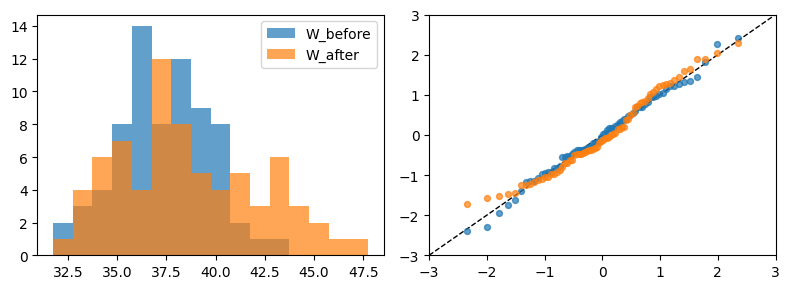

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

w_cols = ["W_before", "W_after"]
w_values = df[w_cols].to_numpy() # w_values = np.array(df[w_cols])
bins = np.arange(w_values.min(), w_values.max() + 1)

for var in w_cols:
    values = df[var]
    axes[0].hist(values, bins=bins, alpha=0.7, label=var)

    z = stats.zscore(values, ddof=1)
    theoretical, observed = stats.probplot(z, dist="norm", fit=False)
    axes[1].scatter(theoretical, observed, s=18, alpha=0.7)

axes[1].plot([-3, 3], [-3, 3], "k--", linewidth=1, zorder=0)
axes[1].set(xlim=(-3, 3), ylim=(-3, 3))
axes[0].legend()

plt.tight_layout()
plt.show()

In [7]:
pd.Series({
    var: stats.shapiro(df[var]).pvalue for var in ["W_before", "W_after"]
}, name="p-value").to_frame()

,p-value
W_before,0.948353
W_after,0.057809


Повторите аналогичную проверку нормальности обоих переменных для всех трех групп.  
Графики изобразите на сетке 3 × 2, а результаты тестов оформите через `pd.DataFrame`.

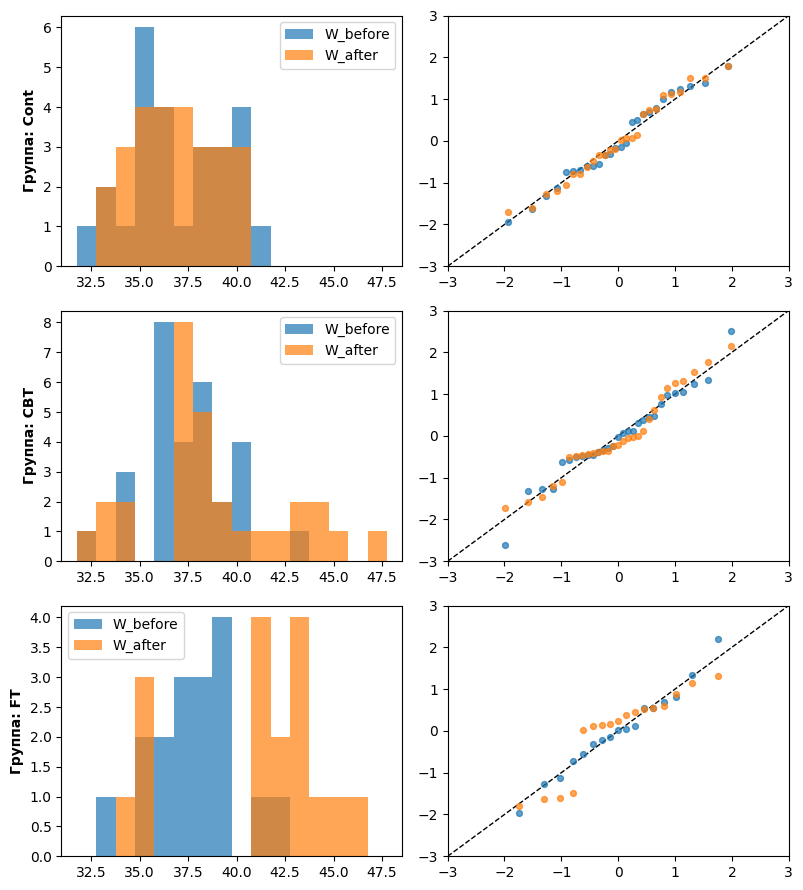

,W_before,W_after
Группа лечения,,
Cont,0.589533,0.543101
CBT,0.557979,0.205747
FT,0.997215,0.007391


In [11]:
w_cols = ["W_before", "W_after"]
w_values = df[w_cols].to_numpy()
bins = np.arange(w_values.min(), w_values.max() + 1)

groups = df["treatment"].unique()
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 9))

shapiro_results = {}

for g_idx, group_name in enumerate(groups):
    group_df = df[df["treatment"] == group_name]
    shapiro_results[group_name] = {}

    for var in w_cols:
        values = group_df[var]
        axes[g_idx, 0].hist(values, bins=bins, alpha=0.7, label=var)

        z = stats.zscore(values, ddof=1)
        theoretical, observed = stats.probplot(z, dist="norm", fit=False)
        axes[g_idx, 1].scatter(theoretical, observed, s=18, alpha=0.7)

        shapiro_results[group_name][var] = stats.shapiro(values).pvalue

    axes[g_idx, 1].plot([-3, 3], [-3, 3], "k--", linewidth=1, zorder=0)
    axes[g_idx, 1].set(xlim=(-3, 3), ylim=(-3, 3))
    axes[g_idx, 0].legend()

    axes[g_idx, 0].set_ylabel(f"Группа: {group_name}", weight="bold")

plt.tight_layout()
plt.show()

df_shapiro = pd.DataFrame(shapiro_results).T
df_shapiro.index.name = "Группа лечения"
df_shapiro

С помощью `.groupby` оцените среднее и стандартное отклонение отдельно для трех групп.

In [ ]:
df.groupby("treatment")[w_cols].agg(["mean", "std"])

W_before              W_after          
                mean       std       mean       std
treatment                                          
CBT        37.507397  2.197879  38.871302  3.788369
Cont       36.993947  2.588679  36.789830  2.151957
FT         37.752226  2.275534  41.047441  3.844228

### Задание 2

Сравним исходный вес в группах `CBT` и `Cont` с помощью t-критерия. За что отвечает параметр `equal_var`? Попробуем выполнить тест с разными его значениями.

In [12]:
control = df.loc[df["treatment"] == "Cont", "W_before"]
cbt = df.loc[df["treatment"] == "CBT", "W_before"]

student = stats.ttest_ind(control, cbt, equal_var=True)
welch = stats.ttest_ind(control, cbt, equal_var=False)

pd.DataFrame({
    "test": ["Student", "Welch"],
    "statistic": [student.statistic, welch.statistic],
    "p-value": [student.pvalue, welch.pvalue],
})

,test,statistic,p-value
0,Student,-0.795370,0.429946
1,Welch,-0.788231,0.434332


Далее по умолчанию будем использовать тест Уэлча. Аналогично выполните проверку на различие среднего веса после терапии для этих двух групп.  
Отвергаем ли мы нулевую гипотезу?

In [13]:
control = df.loc[df["treatment"] == "Cont", "W_after"]
cbt = df.loc[df["treatment"] == "CBT", "W_after"]

welch = stats.ttest_ind(control, cbt, equal_var=False)

pd.DataFrame({
    "test": ["Welch"],
    "statistic": [welch.statistic],
    "p-value": [welch.pvalue],
})

,test,statistic,p-value
0,Welch,-2.537249,0.01469


### Задание 3

Для оценки динамики веса у одной и той же пациентки введем новую переменную:
$$
\Delta W = W_{\mathrm{after}} - W_{\mathrm{before}}.
$$

In [14]:
df["delta_W"] = df["W_after"] - df["W_before"]
df.groupby("treatment", sort=False)["delta_W"].agg(["mean", "std"]).T.round(2)

treatment,Cont,CBT,FT
mean,-0.20,1.36,3.30
std,3.62,3.32,3.25


Оцените распределение новой величины на нормальность для группы `FT`.

In [18]:
stats.shapiro(df.loc[df["treatment"] == "FT", "delta_W"])

ShapiroResult(statistic=np.float64(0.9535845728420317), pvalue=np.float64(0.5156117651291825))

### Задание 4

С помощью парного теста Стьюдента роверьте, изменился ли вес в группе `FT` в среднем. Для этого используйте `stats.ttest_rel`.

In [22]:
ft_after = df.loc[df["treatment"] == "FT", "W_after"]
ft_before = df.loc[df["treatment"] == "FT", "W_before"]

paired_test = stats.ttest_rel(ft_after, ft_before)
pd.DataFrame(
    {
        "Метрика": ["t-статистика", "p-value"],
        "Значение": [paired_test.statistic, paired_test.pvalue],
    }
).round(4)

,Метрика,Значение
0,t-статистика,4.1849
1,p-value,0.0007


Проверьте нулевую гипотезу о том, что среднее изменение веса равно нулю, с помощью одновыборочного t-теста для `delta_W`. Для этого используйте `stats.ttest_1samp` с параметром `popmean=0`. Сравните статистику и p-value с результатом парного t-теста.

In [23]:
ft_data = df[df["treatment"] == "FT"]
one_sample = stats.ttest_1samp(ft_data["delta_W"], popmean=0)

In [25]:
comparison_df = pd.DataFrame(
    {
        "Одновыборочный t-тест (delta_W)": [
            one_sample.statistic,
            one_sample.pvalue,
        ],
        "Парный t-тест (after vs before)": [paired_test.statistic, paired_test.pvalue],
    },
    index=["t-статистика", "p-value"],
)

comparison_df

,Одновыборочный t-тест (delta_W),Парный t-тест (after vs before)
t-статистика,4.184908,4.184908
p-value,0.000700,0.000700


### Задание 5

Проверьте, различается ли среднее изменение веса между группами `CBT` и `FT` с помощью двухвыборочного t-теста Уэлча. Выведите значение статистики и p-value.

In [30]:
cbt = df[df["treatment"] == 'CBT']
ft = df[df["treatment"] == 'FT']

welch_test = stats.ttest_ind(cbt["delta_W"], ft['delta_W'], equal_var=False)
welch_test

TtestResult(statistic=np.float64(-1.9323117761916853), pvalue=np.float64(0.061631129879626545), df=np.float64(34.22913736981994))

In [29]:
pd.DataFrame(
    {
        "Метрика": ["t-статистика Уэлча", "p-value"],
        "Значение": [welch_test.statistic, welch_test.pvalue],
    }
).round(4)

,Метрика,Значение
0,t-статистика Уэлча,-1.9323
1,p-value,0.0616
